In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Dataset Shape: (21263, 82)
Missing Values: 0
Target: critical_temp
Number of Samples: 21263
Number of Features: 81

Training Samples: 14884
Validation Samples: 3189
Testing Samples: 3190

Linear Regression Model Trained Successfully!
Training Time: 0.1966 seconds

========== MODEL PERFORMANCE ==========
             Training  Validation   Testing
MAE           13.2489     13.5801   13.2687
MSE          305.9782    314.1837  316.9004
RMSE          17.4922     17.7252   17.8017
R2             0.7404      0.7316    0.7247
Adjusted_R2    0.7390      0.7246    0.7175

Training Time: 0.1966 seconds
Intercept: 34.50620718456058
Number of Coefficients: 81


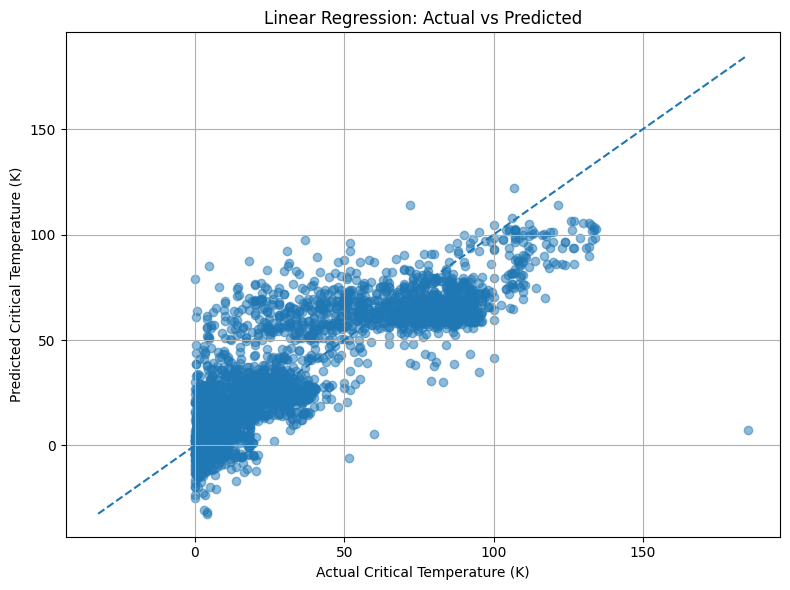

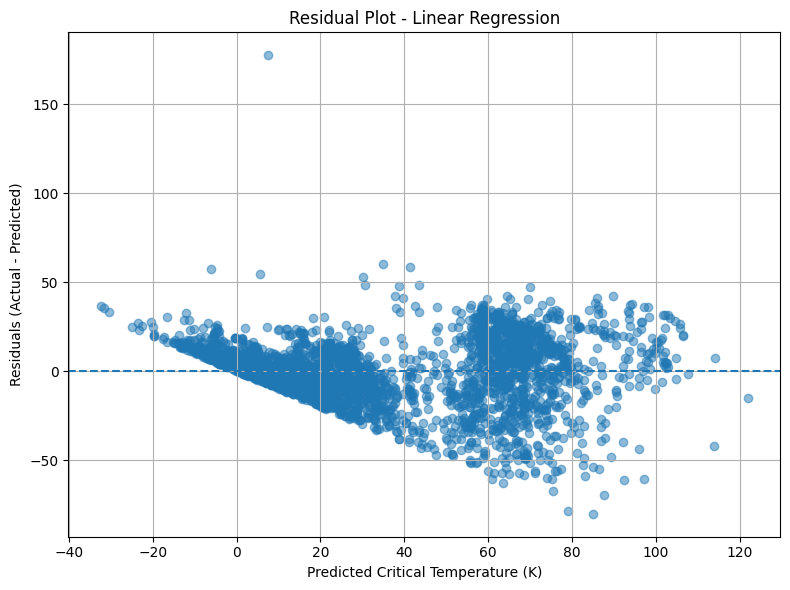


All results saved to:
/content/drive/MyDrive/Linear_Regression_Results

Files generated:
1. evaluation_metrics.csv
2. test_predictions.csv
3. model_coefficients.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import time

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATASET
# --------------------------------------------------

DATA_PATH = "/content/drive/MyDrive/train.csv"
TARGET = "critical_temp"
SEED = 42

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Target:", TARGET)

# Separate input features and target
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Remove rows with missing target values, if any
valid_rows = y.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Number of Samples:", len(df))
print("Number of Features:", X.shape[1])

# --------------------------------------------------
# 2. SPLIT DATA: 70% TRAIN, 15% VALIDATION, 15% TEST
# --------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("\nTraining Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

# --------------------------------------------------
# 3. HANDLE MISSING FEATURE VALUES
# --------------------------------------------------

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

# --------------------------------------------------
# 4. FEATURE SCALING
# --------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# --------------------------------------------------
# 5. TRAIN LINEAR REGRESSION MODEL
# --------------------------------------------------

model = LinearRegression(fit_intercept=True)

start_time = time.time()
model.fit(X_train, y_train)
training_time = time.time() - start_time

print("\nLinear Regression Model Trained Successfully!")
print("Training Time:", round(training_time, 4), "seconds")

# --------------------------------------------------
# 6. PREDICTIONS
# --------------------------------------------------

y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

# --------------------------------------------------
# 7. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate_model(y_true, y_pred, n_features):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    n = len(y_true)

    if n > n_features + 1:
        adjusted_r2 = 1 - (
            (1 - r2) * (n - 1) / (n - n_features - 1)
        )
    else:
        adjusted_r2 = np.nan

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Adjusted_R2": adjusted_r2
    }

# --------------------------------------------------
# 8. EVALUATE TRAINING, VALIDATION AND TEST SETS
# --------------------------------------------------

n_features = X_train.shape[1]

train_metrics = evaluate_model(
    y_train, y_train_pred, n_features
)

val_metrics = evaluate_model(
    y_val, y_val_pred, n_features
)

test_metrics = evaluate_model(
    y_test, y_test_pred, n_features
)

results = pd.DataFrame({
    "Training": train_metrics,
    "Validation": val_metrics,
    "Testing": test_metrics
})

print("\n========== MODEL PERFORMANCE ==========")
print(results.round(4))

print("\nTraining Time:", round(training_time, 4), "seconds")
print("Intercept:", model.intercept_)
print("Number of Coefficients:", len(model.coef_))

# --------------------------------------------------
# 9. ACTUAL VS PREDICTED PLOT
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Critical Temperature (K)")
plt.ylabel("Predicted Critical Temperature (K)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. RESIDUAL PLOT
# --------------------------------------------------

residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_test_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Critical Temperature (K)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")
plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 11. SAVE RESULTS TO GOOGLE DRIVE
# --------------------------------------------------

OUTPUT_DIR = "/content/drive/MyDrive/Linear_Regression_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save evaluation metrics
results.to_csv(
    os.path.join(OUTPUT_DIR, "evaluation_metrics.csv")
)

# Save test predictions
predictions = pd.DataFrame({
    "Actual_Critical_Temp": y_test.to_numpy(),
    "Predicted_Critical_Temp": y_test_pred,
    "Residual": residuals.to_numpy()
})

predictions.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# Save model coefficients
coefficients = pd.DataFrame({
    "Feature": df.drop(columns=[TARGET]).columns,
    "Coefficient": model.coef_
})

coefficients.to_csv(
    os.path.join(OUTPUT_DIR, "model_coefficients.csv"),
    index=False
)

print("\nAll results saved to:")
print(OUTPUT_DIR)

print("\nFiles generated:")
print("1. evaluation_metrics.csv")
print("2. test_predictions.csv")
print("3. model_coefficients.csv")